## Importación de Bibliotecas

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Bibliotecas cargadas correctamente.")

Bibliotecas cargadas correctamente.


## Generación de Datos Sintéticos

In [2]:
# Datos artificiales para demostrar el funcionamiento del pipeline.
# No corresponden a registros medicos reales.

np.random.seed(42)
n = 500

edad_meses = np.random.uniform(0, 6, n)
horas_sueno_diarias = np.random.uniform(10, 18, n)
actividad_motora = np.random.uniform(0, 10, n)

# Relacion artificial utilizada para generar la variable objetivo.
duracion_ciclo = (
    42
    + 3.5 * edad_meses
    + 2.0 * horas_sueno_diarias
    - 0.8 * actividad_motora
    + np.random.normal(0, 5, n)
)

duracion_ciclo = np.clip(duracion_ciclo, 20, 120)

df = pd.DataFrame({
    "edad_meses": edad_meses,
    "horas_sueno_diarias": horas_sueno_diarias,
    "actividad_motora": actividad_motora,
    "duracion_ciclo_min": duracion_ciclo
})

df.head()

,edad_meses,horas_sueno_diarias,actividad_motora,duracion_ciclo_min
0,2.247241,15.585294,1.851329,67.057838
1,5.704286,14.288771,5.419009,97.662048
2,4.391964,12.476221,8.729458,68.392886
3,3.591951,16.510360,7.322249,73.507756
4,0.936112,15.477849,8.065611,74.892453


Los valores se generan mediante una relación artificial conocida y ruido aleatorio. Las asociaciones observadas son parte de la simulación y no deben interpretarse como relaciones fisiológicas demostradas.

## Exploración y Validación de los Datos

In [3]:
print("Dimensiones del dataset:", df.shape)

print("\nInformacion general:")
df.info()

print("\nEstadisticas descriptivas:")
display(df.describe())

print("\nValores faltantes:")
print(df.isnull().sum())

print("\nRegistros duplicados:", df.duplicated().sum())

Dimensiones del dataset: (500, 4)

Informacion general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   edad_meses           500 non-null    float64
 1   horas_sueno_diarias  500 non-null    float64
 2   actividad_motora     500 non-null    float64
 3   duracion_ciclo_min   500 non-null    float64
dtypes: float64(4)
memory usage: 15.8 KB

Estadisticas descriptivas:


,edad_meses,horas_sueno_diarias,actividad_motora,duracion_ciclo_min
count,500.000000,500.000000,500.000000,500.000000
mean,2.991370,13.855611,5.175581,76.340429
std,1.792130,2.283948,2.971929,9.869814
min,0.030370,10.037056,0.049400,52.365587
25%,1.447678,11.832794,2.412280,69.293034
50%,3.078982,13.774573,5.397383,76.046319
75%,4.536749,15.810695,7.773438,83.744574
max,5.957789,17.997741,9.994137,103.313385



Valores faltantes:
edad_meses             0
horas_sueno_diarias    0
actividad_motora       0
duracion_ciclo_min     0
dtype: int64

Registros duplicados: 0


## Visualización Exploratoria

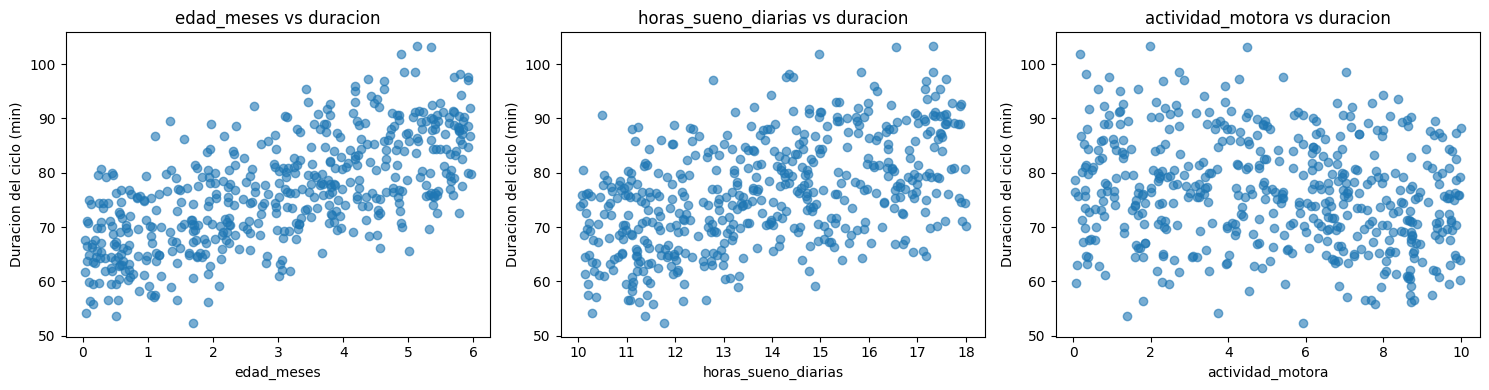

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

variables = [
    "edad_meses",
    "horas_sueno_diarias",
    "actividad_motora"
]

for ax, variable in zip(axes, variables):
    ax.scatter(
        df[variable],
        df["duracion_ciclo_min"],
        alpha=0.6
    )
    ax.set_xlabel(variable)
    ax.set_ylabel("Duracion del ciclo (min)")
    ax.set_title(f"{variable} vs duracion")

plt.tight_layout()
plt.show()

## Selección de Variables y División de Datos

In [5]:
X = df[
    [
        "edad_meses",
        "horas_sueno_diarias",
        "actividad_motora"
    ]
]

y = df["duracion_ciclo_min"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Registros de entrenamiento:", len(X_train))
print("Registros de prueba:", len(X_test))

Registros de entrenamiento: 400
Registros de prueba: 100


El 80 % de los registros se destina al entrenamiento y el 20 % restante a la evaluación. La división se realiza antes de entrenar el modelo para mantener un conjunto de prueba independiente.

## Entrenamiento del Modelo

In [6]:
modelo = RandomForestRegressor(
    n_estimators=100,
    max_depth=8,
    min_samples_leaf=2,
    random_state=42
)

modelo.fit(X_train, y_train)

print("Modelo entrenado correctamente.")

Modelo entrenado correctamente.


## Predicción y Evaluación

In [7]:
y_pred = modelo.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

metricas = pd.DataFrame({
    "Metrica": ["MAE", "RMSE", "R2"],
    "Valor": [mae, rmse, r2]
})

display(metricas)

print(f"MAE: {mae:.2f} minutos")
print(f"RMSE: {rmse:.2f} minutos")
print(f"R2: {r2:.3f}")

,Metrica,Valor
0,MAE,4.497457
1,RMSE,5.868700
2,R2,0.664580


MAE: 4.50 minutos
RMSE: 5.87 minutos
R2: 0.665


Interpretación de las métricas:
- MAE: indica el error absoluto promedio de las predicciones, expresado en minutos.
- RMSE: penaliza con mayor intensidad los errores grandes, también en minutos.
- R²: compara el desempeño del modelo con una referencia basada en la media de los valores reales. Puede ser negativo si el modelo funciona peor que esa referencia.
Los valores numéricos obtenidos deberán interpretarse después de ejecutar el notebook. No se debe afirmar un nivel de precisión antes de observar los resultados.

## Gráfico de Valores Reales Frente a Predicciones

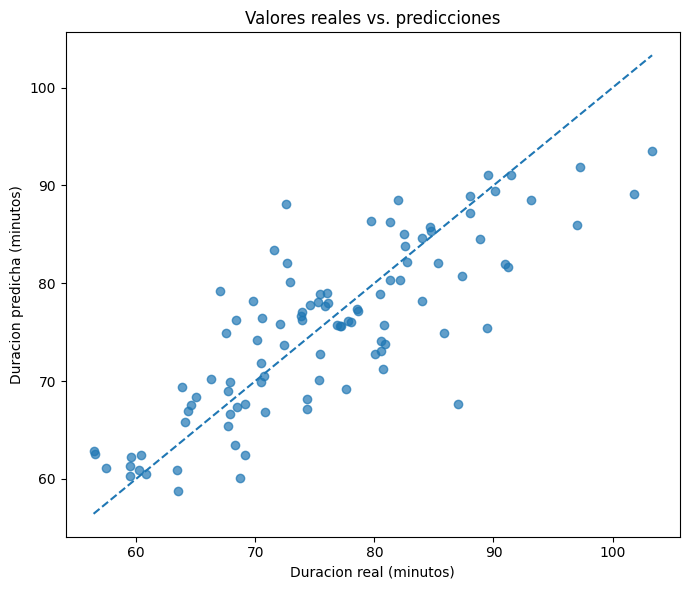

In [8]:
plt.figure(figsize=(7, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

limite_min = min(y_test.min(), y_pred.min())
limite_max = max(y_test.max(), y_pred.max())

plt.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    linestyle="--"
)

plt.xlabel("Duracion real (minutos)")
plt.ylabel("Duracion predicha (minutos)")
plt.title("Valores reales vs. predicciones")
plt.tight_layout()
plt.show()

En este gráfico, los puntos más próximos a la línea diagonal representan predicciones más cercanas a los valores reales. Los puntos alejados de la línea reflejan errores de predicción.

## Importancia de las Variables

,Variable,Importancia
0,edad_meses,0.557236
1,horas_sueno_diarias,0.331398
2,actividad_motora,0.111366


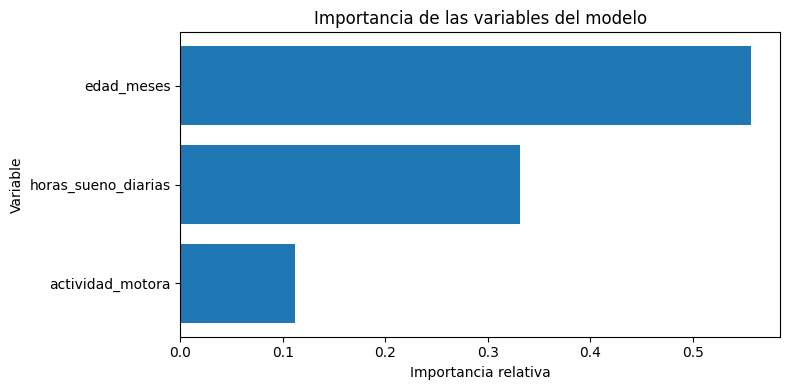

In [9]:
importancias = pd.DataFrame({
    "Variable": X.columns,
    "Importancia": modelo.feature_importances_
}).sort_values("Importancia", ascending=False)

display(importancias)

plt.figure(figsize=(8, 4))

plt.barh(
    importancias["Variable"],
    importancias["Importancia"]
)

plt.xlabel("Importancia relativa")
plt.ylabel("Variable")
plt.title("Importancia de las variables del modelo")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

La importancia de las variables permite observar cuáles contribuyeron más a las predicciones del Random Forest en este conjunto sintético. No demuestra causalidad ni permite concluir que esas variables tengan la misma importancia en datos reales.

## Ejemplo de Predicción

In [10]:
nuevo_registro = pd.DataFrame({
    "edad_meses": [2.0],
    "horas_sueno_diarias": [14.0],
    "actividad_motora": [4.0]
})

prediccion = modelo.predict(nuevo_registro)[0]

print(
    "Duracion estimada del ciclo de sueno:",
    round(prediccion, 2),
    "minutos"
)

Duracion estimada del ciclo de sueno: 76.45 minutos


La cifra que se muestre será una estimación generada por el modelo entrenado con datos artificiales. No debe utilizarse para tomar decisiones sobre el cuidado o la salud de un recién nacido.